In [ ]:
import pandas as pd

# Load Data

In [ ]:
# data = pd.read_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\tonghopdata.csv')

data = pd.read_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\GSE183635_TEP_Count_Matrix.csv')
# name_gene =  pd.read_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\183635\Human_CH38p13annot.csv', low_memory=False    )


In [ ]:
data

In [ ]:
import numpy as np

# Minimal TMM normalization adapted from edgeR logic
# Returns CPM and factors scaled so geometric mean of factors is 1.
def compute_tmm_cpm(counts_df, trim_M=0.3, trim_A=0.05, ref_sample=None):
    counts = counts_df.copy()
    lib_sizes = counts.sum(axis=0)

    # Pick reference sample: closest library size to median if none provided
    if ref_sample is None:
        ref_sample = (lib_sizes - lib_sizes.median()).abs().idxmin()
    ref_counts = counts[ref_sample]
    lib_ref = lib_sizes[ref_sample]

    factors = {}

    def tmm_factor(test_counts, lib_test):
        mask = (test_counts > 0) & (ref_counts > 0)
        if mask.sum() == 0:
            return 1.0

        test = test_counts[mask]
        ref = ref_counts[mask]

        logR = np.log2((test / lib_test) / (ref / lib_ref))
        logA = 0.5 * np.log2((test / lib_test) * (ref / lib_ref))
        weights = 1.0 / ((1.0 / test) + (1.0 / ref))

        # Trim extremes on M and A
        m_low, m_high = np.quantile(logR, [trim_M / 2, 1 - trim_M / 2])
        a_low, a_high = np.quantile(logA, [trim_A / 2, 1 - trim_A / 2])
        keep = (logR >= m_low) & (logR <= m_high) & (logA >= a_low) & (logA <= a_high)

        if keep.sum() == 0:
            return 1.0

        weighted_M = np.average(logR[keep], weights=weights[keep])
        return 2 ** weighted_M

    for col in counts.columns:
        factors[col] = tmm_factor(counts[col], lib_sizes[col])

    factors = pd.Series(factors)
    factors = factors / np.exp(np.log(factors).mean())  # rescale to geometric mean 1
    effective_lib_sizes = lib_sizes * factors

    cpm = counts.divide(effective_lib_sizes, axis=1) * 1_000_000
    return cpm, factors, effective_lib_sizes

In [ ]:
# Apply TMM normalization → CPM → log2(CPM+1)
count_cols = data.columns.drop('Unnamed: 0')
counts_numeric = data[count_cols].apply(pd.to_numeric, errors='coerce').fillna(0)

# TMM factors trimmed at 30% for M and 5% for A (edgeR defaults)
tmm_cpm, tmm_factors, tmm_libsizes = compute_tmm_cpm(
    counts_numeric,
    trim_M=0.3,
    trim_A=0.05,
)

tmm_log2 = np.log2(tmm_cpm + 1)

# Reattach gene column and use the normalized values for downstream steps
tmm_log2.insert(0, 'Unnamed: 0', data['Unnamed: 0'])
raw_counts = data.copy()
data = tmm_log2

tmm_log2.head()

In [ ]:
data

In [ ]:
data.drop_duplicates(inplace=True)

In [ ]:
# Transpose so samples become rows
data_transposed = data.set_index('Unnamed: 0').T
data_transposed

In [ ]:
# data_transposed.to_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\otherdata can be merged\raw.csv', index=True )

In [ ]:
data_transposed['cancer_type'] = (
    data_transposed['cancer_type']
    .replace('Other/Unknown', 'Asymptomatic_Controls')
)


In [ ]:
data_transposed['cancer_type'].value_counts()

In [ ]:
# Extract the names of the remaining 338
remaining_unknowns = [c for c in data.columns if categorize_tumor_type(c) == 'Other/Unknown']

# Look for patterns

print(pd.Series(remaining_unknowns).head(44))

In [ ]:
data_transposed = data_transposed[
    data_transposed['cancer_type'] != 'Symptomatic_Control'
]

In [ ]:
data_transposed.reset_index(drop=True, inplace=True)


In [ ]:
data_transposed

In [ ]:
# 4) Filter low-expression genes (expressed in ≥10% of samples)
min_samples = len(data_transposed) * 0.01
gene_cols = data_transposed.columns.drop('cancer_type')
expressed_genes_mask = (data_transposed[gene_cols] > 0).sum(axis=0) >= min_samples
data_filtered = data_transposed.loc[:, expressed_genes_mask.index[expressed_genes_mask]]
data_filtered['cancer_type'] = data_transposed['cancer_type']


In [ ]:

import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier


In [ ]:
from sklearn.preprocessing import MinMaxScaler

In [ ]:
data_normalized = data_filtered.copy()

In [ ]:
# # # 5) MinMax normalize gene expression values
# # data_normalized = data_filtered.copy()

# # Get gene columns (exclude cancer_type)
# gene_cols = data_normalized.columns.drop('cancer_type')

# # Initialize MinMaxScaler
# scaler = MinMaxScaler()

# # Fit and transform only the gene expression columns
# data_normalized[gene_cols] = scaler.fit_transform(data_filtered[gene_cols])

# # Keep cancer_type column
# data_normalized['cancer_type'] = data_filtered['cancer_type']


In [ ]:
data_normalized

In [ ]:
# 6) Split features/labels
X = data_normalized.drop(columns=['cancer_type'])
y = data_normalized['cancer_type']


In [ ]:
X

In [ ]:
# y.to_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Multi\data\y_multi_ori.csv', index=False)

In [ ]:
# X.to_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Multi\data\normalized_X_multi_log.csv', index=False)

In [ ]:
X.to_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\data\X_normalized_binary_log.csv', index=False)

In [ ]:
y = y.apply(lambda x: 1 if x != 'Asymptomatic_Controls' and x != 'Symptomatic_Control' else 0)

In [ ]:
y.value_counts()

In [ ]:
y.to_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\data\y_normalized_binary.csv', index=False)

# embedded RF with stratify k fold

In [ ]:
import pandas as pd
import numpy as np
import json
import warnings
from pathlib import Path
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')

# Set random state for reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [ ]:
X = pd.read_csv(r"D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\data\X_normalized_binary_log.csv", low_memory=False)
y = pd.read_csv(r"D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\data\y_normalized_binary.csv", low_memory=False).values.ravel()


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=True, random_state=42)

In [ ]:

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_train)
gene_names = X_train.columns.values

In [ ]:
print("  This may take a few minutes...")

# Parameter grid for RandomForest
param_grid_rf = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 20, 30, None],
    'min_samples_split': [2, 5]
}

# RandomForest classifier
rf = RandomForestClassifier(
    random_state=RANDOM_STATE,
    class_weight='balanced',
    n_jobs=-1
)

# Stratified K-Fold
cv_inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Grid search
grid_search_rf = GridSearchCV(
    rf,
    param_grid_rf,
    cv=cv_inner,
    scoring='accuracy',
    n_jobs=-1,
    verbose=0
)

grid_search_rf.fit(X_scaled, y_train)

# Get feature importances
best_rf = grid_search_rf.best_estimator_
feature_importances = best_rf.feature_importances_

### Ranking all genes by RandomForest importance...

In [ ]:
# Create dataframe with ALL genes and their importance scores
rf_df = pd.DataFrame({
    'gene': gene_names,
    'importance': feature_importances
})
rf_df = rf_df.sort_values('importance', ascending=False)

In [ ]:
rf_df.to_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\data\data ranked rf sk\feature_importance.csv', index=False)

In [ ]:
all_features = (
    rf_df.sort_values('importance', ascending=False)
    .head(5440)['gene']
    .tolist()
)

In [ ]:
X_train[all_features]

In [ ]:
X_train[all_features].to_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\data\data ranked rf sk\ranking_features.csv', index=False)

In [ ]:
# import matplotlib.pyplot as plt
# plt.figure(figsize=(6, 6))
# plt.barh(importance_df['Feature'], importance_df['Importance'], color='blue')
# plt.xlabel('Importance Score')
# plt.ylabel('Feature')
# plt.title('Feature Importance Scores from Random Forest')
# plt.gca().invert_yaxis()  # To display the highest importance at the top
# plt.show()

# Start ML


In [71]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

In [72]:
X_train = pd.read_csv(r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2_lung\Binary\data\ranked rf\X_train_rF_DEG_train_lung.csv",low_memory = False)
X_test = pd.read_csv(r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2_lung\Binary\data\ranked rf\X_test_rF_DEG_train_lung.csv",low_memory = False)

y_train = pd.read_csv(r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2_lung\Binary\data\ranked rf\y_train_rF_DEG_train.csv",low_memory = False)
y_test = pd.read_csv(r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2_lung\Binary\data\ranked rf\y_test_rF_DEG_train.csv",low_memory = False)

In [42]:
X_test

,ENSG00000227165,ENSG00000111196,ENSG00000240225,ENSG00000142089,ENSG00000130948,ENSG00000103512,ENSG00000142856,ENSG00000249307,ENSG00000163359,ENSG00000260661,...,ENSG00000186166,ENSG00000007392,ENSG00000197635,ENSG00000012223,ENSG00000137509,ENSG00000115590,ENSG00000052749,ENSG00000161944,ENSG00000129824,ENSG00000173535
0,6.451547,5.348242,5.063048,7.340270,4.175718,5.665411,8.002006,4.625584,5.027229,3.306779,...,4.346157,4.521600,3.711639,2.830723,4.138130,2.830723,2.830723,2.830723,5.742559,2.830723
1,6.630307,5.769564,5.769564,3.921878,4.450995,5.844078,6.824695,4.551511,5.373541,3.728479,...,4.886915,5.026358,3.470567,7.424813,5.026358,3.921878,6.730802,4.644246,2.830723,3.921878
2,4.806340,4.468396,2.830723,7.664287,3.783802,4.345067,4.579964,3.783802,6.068926,2.830723,...,6.057216,6.159271,2.830723,2.830723,4.972535,3.988061,3.783802,6.068926,7.984931,4.579964
3,6.948542,6.390590,5.743158,5.220952,3.531932,6.448757,7.818158,4.996651,4.023021,4.564307,...,3.751771,3.531932,2.830723,4.535230,2.830723,3.328968,4.023021,2.830723,2.830723,3.924027
4,7.263197,6.852681,6.983045,5.905861,4.972501,6.667009,7.623942,4.838434,3.564025,4.543893,...,2.830723,3.401148,2.830723,2.830723,4.221185,3.161482,2.830723,3.401148,5.322133,3.161482
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
178,7.793642,7.068577,6.270715,4.704627,5.540731,6.599390,9.150536,4.909011,5.282180,4.881746,...,2.830723,2.830723,2.830723,2.830723,3.223397,2.830723,2.830723,3.223397,3.223397,2.830723
179,6.029134,4.743265,5.561667,4.795813,3.522366,4.875604,7.151842,3.920887,5.369384,3.897971,...,2.830723,3.441971,2.830723,2.830723,3.063233,2.830723,2.830723,2.830723,2.830723,2.830723
180,6.585824,4.597360,5.647809,6.105820,4.280496,6.059986,8.286562,4.396034,6.193255,4.339747,...,4.848015,5.493568,2.830723,2.830723,2.830723,2.830723,4.449686,3.610574,6.044371,4.217875
181,4.978482,4.240479,4.631622,7.745341,2.830723,4.926833,6.610647,3.773898,5.122217,3.605274,...,3.913699,2.830723,2.830723,2.830723,3.913699,2.830723,2.830723,2.830723,5.166854,3.381660


In [73]:
import pandas as pd
import mygene

# 2. Extract the Ensembl IDs
# We filter for columns starting with 'ENSG' to avoid messing up index columns like 'Unnamed: 0'
ensembl_ids = [col for col in X_train.columns if col.startswith('ENSG')]

# (Optional) If your IDs have decimals like 'ENSG00000096060.1', you need to strip them:
# ensembl_ids = [col.split('.')[0] for col in ensembl_ids]

# 3. Query the MyGene Database
print("Querying MyGene.info for gene symbols...")
mg = mygene.MyGeneInfo()
results = mg.querymany(ensembl_ids, scopes='ensembl.gene', fields='symbol', species='human')

# 4. Create a mapping dictionary { 'ENSG_ID' : 'Gene_Symbol' }
id_to_symbol = {}
for res in results:
    query_id = res['query']
    
    # If a gene symbol is found, use it. Otherwise, keep the original Ensembl ID.
    if 'symbol' in res:
        id_to_symbol[query_id] = res['symbol']
    else:
        id_to_symbol[query_id] = query_id

# 5. Rename the columns in both DataFrames
X_train.rename(columns=id_to_symbol, inplace=True)
X_test.rename(columns=id_to_symbol, inplace=True)

print("Conversion complete!")
print("Preview of new columns in X_train:")
print(X_train.head())

Querying MyGene.info for gene symbols...


5 input query terms found no hit:	['ENSG00000197459', 'ENSG00000267243', 'ENSG00000136653', 'ENSG00000163386', 'ENSG00000148362']


Conversion complete!
Preview of new columns in X_train:
   WDR11-DT    MAGOHB   ZNF542P    IFITM3   HSD17B3     NOMO1   ITGB3BP  \
0  5.590922  4.920421  4.513914  6.808245  3.643703  5.229449  5.296728   
1  7.111388  6.283755  6.129917  4.970461  4.523772  7.441317  7.797965   
2  4.176511  3.782071  2.764579  7.538766  2.764579  3.782071  4.889779   
3  5.002632  4.644839  3.753215  5.804742  2.764579  4.836138  6.369995   
4  6.255441  5.619431  4.050363  7.027353  3.522978  4.234493  6.180337   

   LINC01088    COL6A3  ENSG00000260661  ...   CENATAC     LUC7L      DPP4  \
0   3.774722  5.391791         2.764579  ...  3.485998  4.452266  3.485998   
1   4.749558  3.944942         3.610526  ...  2.764579  3.944942  3.192072   
2   2.764579  4.889779         4.176511  ...  5.344660  6.186679  2.764579   
3   3.753215  4.137808         2.764579  ...  6.427103  7.613563  4.137808   
4   4.050363  5.435232         2.764579  ...  5.367917  5.435232  2.764579   

        LTF      PRCP   

In [44]:
X_train = X_train.iloc[:,:208]
# 0.0015

In [45]:
X_test = X_test.iloc[:,:208]

In [46]:
from xgboost import XGBClassifier

In [47]:
from sklearn.model_selection import StratifiedKFold

In [48]:
from sklearn.preprocessing import StandardScaler
scale = StandardScaler()
x_train_sc = scale.fit_transform(X_train)
x_test_sc = scale.transform(X_test)

In [49]:
list_feature = list(X_train.columns)

In [50]:
ranks = []
for i in range(len(list_feature)):
    arr = []
    for j in range(i+1):
        arr.append(list_feature[j])
    ranks.append(arr)

In [51]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from xgboost import XGBClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import StratifiedKFold
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

In [52]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

In [53]:
from sklearn.metrics import confusion_matrix,roc_auc_score
def cfm(y_test,y_pred,y_prob):
    auc = roc_auc_score(y_test,y_prob)
    tn,fp,fn,tp = confusion_matrix(y_test,y_pred).ravel()
    acc = accuracy_score(y_test,y_pred)
    recall = tp/(tp+fn)
    precision = tp/(tp+fp)
    specificity = tn/(tn+fp)
    sensitivity = tp / (tp+fn)
    f1_score = round((2*recall*precision)/(recall+precision),3)
    return np.array([acc,recall,precision,specificity,sensitivity,f1_score,auc])

# Grid search

In [55]:
import numpy as np
import pandas as pd
from xgboost import XGBClassifier # ADDED
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer, recall_score, confusion_matrix, accuracy_score, roc_curve

# --- 1. Custom Scorers ---
def specificity_score(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    if cm.shape == (2, 2):
        tn, fp, fn, tp = cm.ravel()
        return tn / (tn + fp)
    return 0.0

def balanced_accuracy_medical(y_true, y_pred):
    sn = recall_score(y_true, y_pred, zero_division=0)
    sp = specificity_score(y_true, y_pred)
    return (sn + sp) / 2

scoring_metrics = {
    'ACC': 'accuracy',
    'Recall': 'recall',
    'Precision': 'precision',
    'Sp': make_scorer(specificity_score),
    'Sn': 'recall',
    'f1_Score': 'f1',
    'AUC': 'roc_auc',
    'BA': make_scorer(balanced_accuracy_medical) 
}

# --- 2. Grid Search Setup ---
# Calculate ratio: 391 / 1628 approx 0.24 to handle imbalance
imbalance_ratio = 391 / 522

model = XGBClassifier(
    random_state=11, 
    n_jobs=-1, 
    eval_metric='logloss',
    scale_pos_weight=imbalance_ratio # ADDED: Fixes low Specificity
)

params = {
    'n_estimators': [1000, 1500, 4000],
    'learning_rate': [0.001, 0.03, 0.08],
    'subsample': [0.7, 0.8],
    'colsample_bytree': [0.7, 0.8],
}

grid_search = GridSearchCV(
    estimator=model, 
    param_grid=params, 
    cv=5, 
    scoring=scoring_metrics, 
    refit='BA', # Selection based on (Sn + Sp) / 2
    n_jobs=-1,
    verbose=2
)

# --- 3. The Feature Ranking Loop ---
result = []
result2 = []

for i, rank in enumerate(ranks[10:], start=10):
    grid_search.fit(x_train_sc[:, :i+1], y_train['cancer_type'])
    
    best_idx = grid_search.best_index_
    cv_res = grid_search.cv_results_
    best_model = grid_search.best_estimator_
    
    def fmt(metric):
        return f"{cv_res[f'mean_test_{metric}'][best_idx] * 100:.2f}%"
    
    # THRESHOLD LOCK LOGIC
    y_prob_train = best_model.predict_proba(x_train_sc[:, :i+1])[:, 1]
    fpr_tr, tpr_tr, thresholds_tr = roc_curve(y_train['cancer_type'], y_prob_train)
    
    # Youden's J statistic
    best_threshold = thresholds_tr[np.argmax(tpr_tr - fpr_tr)]

    # Append Training Result
    result.append([
        rank, fmt('ACC'), fmt('Recall'), fmt('Precision'), 
        fmt('Sp'), fmt('Sn'), fmt('f1_Score'), fmt('AUC'), 
        grid_search.best_params_
    ])

    # Save training progress
    df_result = pd.DataFrame(result, columns=['Gene','ACC','Recall','Precision','Sp','Sn','f1_Score','AUC','Parameter'])
    df_result.to_csv(r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2_lung\Binary\data\sfs\XGB_on_training_6_6.csv", index=False)

    # TEST SET PREDICTION
    y_prob_test = best_model.predict_proba(x_test_sc[:, :i+1])[:, 1]
    y_pred_test = (y_prob_test >= best_threshold).astype(int)
    
    # Evaluate using your cfm function (ensure it is loaded in your environment)
    evaluate = cfm(y_test, y_pred_test, y_prob_test)
    
    result2.append([
        rank,
        '%.2f'%(evaluate[0]*100)+'%', # ACC
        '%.2f'%(evaluate[1]*100)+'%', # Recall/Sn
        '%.2f'%(evaluate[2]*100)+'%', # Precision
        '%.2f'%(evaluate[3]*100)+'%', # Sp
        '%.2f'%(evaluate[4]*100)+'%', # Sn
        '%.2f'%(evaluate[5]*100)+'%', # f1
        '%.2f'%(evaluate[6]*100)+'%', # AUC
        grid_search.best_params_
    ])

    df_result2 = pd.DataFrame(result2, columns=['Gene','ACC','Recall','Precision','Sp','Sn','f1_Score','AUC','Parameter'])
    df_result2.to_csv(r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2_lung\Binary\data\sfs\XGB_DEG_on_training(test_selected)_6_6.csv", index=False)

Fitting 5 folds for each of 36 candidates, totalling 180 fits
Fitting 5 folds for each of 36 candidates, totalling 180 fits
Fitting 5 folds for each of 36 candidates, totalling 180 fits
Fitting 5 folds for each of 36 candidates, totalling 180 fits
Fitting 5 folds for each of 36 candidates, totalling 180 fits
Fitting 5 folds for each of 36 candidates, totalling 180 fits
Fitting 5 folds for each of 36 candidates, totalling 180 fits
Fitting 5 folds for each of 36 candidates, totalling 180 fits
Fitting 5 folds for each of 36 candidates, totalling 180 fits
Fitting 5 folds for each of 36 candidates, totalling 180 fits
Fitting 5 folds for each of 36 candidates, totalling 180 fits
Fitting 5 folds for each of 36 candidates, totalling 180 fits
Fitting 5 folds for each of 36 candidates, totalling 180 fits
Fitting 5 folds for each of 36 candidates, totalling 180 fits
Fitting 5 folds for each of 36 candidates, totalling 180 fits
Fitting 5 folds for each of 36 candidates, totalling 180 fits
Fitting 

# plotting sfs

In [ ]:

import ast
import matplotlib.pyplot as plt
import pandas as pd

# -------- settings you can change --------
min_features = 100
max_features = 400

y_min = 85
y_max = 100

# 👉 Select metrics you want to plot
metrics = ["ACC", "AUC", "Recall", "Precision", "f1_Score"]  
# Example:
# metrics = ["ACC", "Recall", "Precision"]
# ----------------------------------------

df_plot = df_result.copy()

# Convert selected metrics from % to float
for m in metrics:
    df_plot[m] = df_plot[m].str.replace("%", "", regex=False).astype(float)

# Count number of selected genes
def count_features(gene_value):
    if isinstance(gene_value, list):
        return len(gene_value)
    try:
        return len(ast.literal_eval(gene_value))
    except:
        return None

df_plot["Num_Features"] = df_plot["Gene"].apply(count_features)

# Filter feature range
df_plot = df_plot[
    (df_plot["Num_Features"] >= min_features) & 
    (df_plot["Num_Features"] <= max_features)
]

# Group by number of features (average values)
df_plot = df_plot.groupby("Num_Features", as_index=False)[metrics].mean()

# Plot
plt.figure(figsize=(10, 6))

markers = ["o", "s", "^", "D", "x", "*"]  # different markers for clarity

for i, m in enumerate(metrics):
    plt.plot(df_plot["Num_Features"], df_plot[m],
             marker=markers[i % len(markers)],
             label=m)

plt.xlabel("Number of Selected Features")
plt.ylabel("Value (%)")
plt.title(f"Metrics vs Number of Selected Features ({min_features}–{max_features})")

plt.ylim(y_min, y_max)

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [63]:

save_path = r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2_lung\Binary\data\sfs\XGB_on_training_6_6.csv"
df_result = pd.read_csv(save_path, low_memory =False)


df_result2 = pd.read_csv(r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2_lung\Binary\data\sfs\XGB_DEG_on_training(test_selected)_6_6.csv", low_memory=False)


In [ ]:
df_result

,Gene,ACC,Recall,Precision,Sp,Sn,f1_Score,AUC,Parameter
0,"['WDR11-DT', 'MAGOHB', 'ZNF542P', 'IFITM3', 'H...",80.68%,79.15%,86.00%,82.75%,79.15%,82.39%,89.44%,"{'colsample_bytree': 0.8, 'learning_rate': 0.0..."
1,"['WDR11-DT', 'MAGOHB', 'ZNF542P', 'IFITM3', 'H...",82.05%,80.83%,86.95%,83.73%,80.83%,83.72%,89.02%,"{'colsample_bytree': 0.7, 'learning_rate': 0.0..."
2,"['WDR11-DT', 'MAGOHB', 'ZNF542P', 'IFITM3', 'H...",83.01%,81.79%,87.67%,84.67%,81.79%,84.61%,90.17%,"{'colsample_bytree': 0.7, 'learning_rate': 0.0..."
3,"['WDR11-DT', 'MAGOHB', 'ZNF542P', 'IFITM3', 'H...",82.19%,81.54%,86.54%,83.08%,81.54%,83.94%,89.68%,"{'colsample_bytree': 0.8, 'learning_rate': 0.0..."
4,"['WDR11-DT', 'MAGOHB', 'ZNF542P', 'IFITM3', 'H...",84.38%,81.80%,90.04%,87.86%,81.80%,85.62%,91.81%,"{'colsample_bytree': 0.8, 'learning_rate': 0.0..."
...,...,...,...,...,...,...,...,...,...
193,"['WDR11-DT', 'MAGOHB', 'ZNF542P', 'IFITM3', 'H...",89.86%,87.77%,94.10%,92.66%,87.77%,90.82%,95.55%,"{'colsample_bytree': 0.7, 'learning_rate': 0.0..."
194,"['WDR11-DT', 'MAGOHB', 'ZNF542P', 'IFITM3', 'H...",90.00%,87.05%,95.03%,93.93%,87.05%,90.86%,95.55%,"{'colsample_bytree': 0.8, 'learning_rate': 0.0..."
195,"['WDR11-DT', 'MAGOHB', 'ZNF542P', 'IFITM3', 'H...",90.00%,87.05%,95.01%,93.94%,87.05%,90.85%,95.63%,"{'colsample_bytree': 0.7, 'learning_rate': 0.0..."
196,"['WDR11-DT', 'MAGOHB', 'ZNF542P', 'IFITM3', 'H...",89.86%,87.05%,94.77%,93.61%,87.05%,90.74%,95.62%,"{'colsample_bytree': 0.7, 'learning_rate': 0.0..."


In [ ]:
# df_result.to_csv(r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2\Binary\data\sfs\XGB_DEG_TPE.csv", index=False)

In [ ]:
xxx

In [64]:
for col in ["ACC", "Recall", "Precision", "Sp", "Sn", "f1_Score", "AUC"]:
    df_result[col] = df_result[col].str.rstrip("%").astype(float)

In [65]:
for col in ["ACC", "Recall", "Precision", "Sp", "Sn", "f1_Score", "AUC"]:
    df_result2[col] = df_result2[col].str.rstrip("%").astype(float)

In [66]:
# 1. Apply the Standard Definition of Balanced Accuracy
df_result['BA'] = (df_result['Sn'] + df_result['Sp']) / 2

In [67]:
# 1. Apply the Standard Definition of Balanced Accuracy
df_result2['BA'] = (df_result2['Sn'] + df_result2['Sp']) / 2

In [99]:
# Use '&' to ensure BOTH conditions are met
sp_threshold = 0
auc_threshold = 0
pre = 0
# This creates a strict filter
mask = (df_result["Sp"] >= sp_threshold) & (df_result["AUC"] >= auc_threshold) & (df_result["Precision"] >= pre)
filtered_df = df_result[mask]

if not filtered_df.empty:
    best_row = filtered_df.loc[filtered_df["AUC"].idxmax()]
    print("Best Model Meeting Strict Criteria:")
    print(best_row)
else:
    print(f"No models found with Sp > {sp_threshold} and AUC > {auc_threshold}.")
    # Optional: see what the highest Sp available is
    print(f"Max Sp in data: {df_result['Sp'].max()}")

Best Model Meeting Strict Criteria:
Gene         ['WDR11-DT', 'MAGOHB', 'ZNF542P', 'IFITM3', 'H...
ACC                                                       91.1
Recall                                                   90.65
Precision                                                 93.6
Sp                                                       91.69
Sn                                                       90.65
f1_Score                                                 92.09
AUC                                                      96.36
Parameter    {'colsample_bytree': 0.7, 'learning_rate': 0.0...
BA                                                       91.17
Name: 65, dtype: object


In [69]:
df_result2.iloc[65]
# ACC 227 -> acc 89.6
# Recall 231
# Precision 194
# Sp 194
# Sn 231 -> acc 89.36
# AUC 306

Gene         ['WDR11-DT', 'MAGOHB', 'ZNF542P', 'IFITM3', 'H...
ACC                                                      87.43
Recall                                                    78.1
Precision                                                100.0
Sp                                                       100.0
Sn                                                        78.1
f1_Score                                                  87.7
AUC                                                       95.6
Parameter    {'colsample_bytree': 0.7, 'learning_rate': 0.0...
BA                                                       89.05
Name: 65, dtype: object

In [ ]:
df_result.loc[df_result["BA"].idxmax()]
# ACC 210
# AUC 92.6
# Sp 227
# BA 194

In [ ]:
df_result.loc[df_result["BA"].idxmax()]

In [ ]:
best_genes = df_result.loc[df_result["BA"].idxmax(), "Gene"]

In [ ]:
# percent_cols = ["ACC", "Recall", "Precision", "Sp", "Sn", "f1_Score", "AUC"]

# for col in percent_cols:
#     df_result[col] = df_result[col].str.rstrip("%").astype(float)

In [ ]:
import ast

# Convert string → list
best_genes = ast.literal_eval(best_genes)

In [ ]:
len(best_genes)

In [ ]:

# Select features
X_train = X_train[best_genes]
X_test  = X_test[best_genes]

In [ ]:
X_train

# Test set

In [74]:
import numpy as np
import pandas as pd
import time
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import make_scorer, recall_score, confusion_matrix, classification_report, roc_curve, auc
# Preserve true gene names before converting DataFrames to numpy arrays
# --- 1. Subset Selection (76 Genes) ---
X_train = X_train.iloc[:, :76]
X_test = X_test.iloc[:, :76]
gene_names_selected = X_train.columns.tolist()
# --- 2. Scaling ---
scale = StandardScaler()
X_train = scale.fit_transform(X_train)
X_test = scale.transform(X_test)

In [100]:
import numpy as np
import pandas as pd
from xgboost import XGBClassifier # ADDED
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer, recall_score, confusion_matrix, accuracy_score, roc_curve

# --- 1. Custom Scorers ---
def specificity_score(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    if cm.shape == (2, 2):
        tn, fp, fn, tp = cm.ravel()
        return tn / (tn + fp)
    return 0.0

def balanced_accuracy_medical(y_true, y_pred):
    sn = recall_score(y_true, y_pred, zero_division=0)
    sp = specificity_score(y_true, y_pred)
    return (sn + sp) / 2

scoring_metrics = {
    'ACC': 'accuracy',
    'Recall': 'recall',
    'Precision': 'precision',
    'Sp': make_scorer(specificity_score),
    'Sn': 'recall',
    'f1_Score': 'f1',
    'AUC': 'roc_auc',
    'BA': make_scorer(balanced_accuracy_medical) 
}

# --- 2. Grid Search Setup ---
# Calculate ratio: 391 / 1628 approx 0.24 to handle imbalance
imbalance_ratio = 391 / 522 

model = XGBClassifier(
    random_state=11, 
    n_jobs=-1, 
    eval_metric='logloss',
    scale_pos_weight=imbalance_ratio # ADDED: Fixes low Specificity
)

params = {
    'n_estimators': [1500],
    'learning_rate': [0.03],
    'subsample': [0.7],
    'colsample_bytree': [0.7],
# {'colsample_bytree': 0.7, 'learning_rate': 0.03, 'n_estimators': 1500, 'subsample': 0.7}
}

grid_search = GridSearchCV(
    estimator=model, 
    param_grid=params, 
    cv=5, 
    scoring=scoring_metrics, 
    refit='BA', # Selection based on (Sn + Sp) / 2
    n_jobs=-1,
    verbose=2
)

In [101]:
import time
start_time = time.time()
grid_search.fit(X_train, y_train['cancer_type'])
end_time = time.time()

Fitting 5 folds for each of 1 candidates, totalling 5 fits


In [102]:
# best_idx = grid_search.best_index_
# cv_res = grid_search.cv_results_
# best_model = grid_search.best_estimator_

# def fmt(metric):
#     return f"{cv_res[f'mean_test_{metric}'][best_idx] * 100:.2f}%"

# # THRESHOLD LOCK LOGIC
# y_prob_train = best_model.predict_proba(X_train)[:, 1]
# fpr_tr, tpr_tr, thresholds_tr = roc_curve(y_train['cancer_type'], y_prob_train)

# # Youden's J statistic
# best_threshold = thresholds_tr[np.argmax(tpr_tr - fpr_tr)]
# result = []
# # Append Training Result
# result.append([
#      fmt('ACC'), fmt('Recall'), fmt('Precision'), 
#     fmt('Sp'), fmt('Sn'), fmt('f1_Score'), fmt('AUC'), 
#     grid_search.best_params_
# ])

In [103]:
# df_result = pd.DataFrame(result, columns=['ACC','Recall','Precision','Sp','Sn','f1_Score','AUC','Parameter'])
# df_result
# for col in ["ACC", "Recall", "Precision", "Sp", "Sn", "f1_Score", "AUC"]:
#     df_result[col] = df_result[col].str.rstrip("%").astype(float)
# # 1. Apply the Standard Definition of Balanced Accuracy
# df_result['BA'] = (df_result['Sn'] + df_result['Sp']) / 2
# y_prob = best_model.predict_proba(X_test)[:, 1]
# y_pred = (y_prob >= best_threshold).astype(int)

In [104]:
import pandas as pd
import numpy as np

results = grid_search.cv_results_
df_results = pd.DataFrame(results)

# Match exactly your scoring dict keys
metrics = ['ACC', 'Recall', 'Precision', 'Sp', 'Sn', 'f1_Score', 'AUC', 'BA']

# Compute variance for all metrics
for m in metrics:
    df_results[f'var_test_{m}'] = df_results[f'std_test_{m}'] ** 2

# Build summary table
cols = ['params']
for m in metrics:
    cols += [f'mean_test_{m}', f'std_test_{m}', f'var_test_{m}']
cols.append('rank_test_BA')

summary_table = df_results[cols].sort_values('rank_test_BA')

# Optional: scale to percentage and round
for m in metrics:
    summary_table[f'mean_test_{m}'] = (summary_table[f'mean_test_{m}'] * 100).round(4)
    summary_table[f'std_test_{m}']  = (summary_table[f'std_test_{m}']  * 100).round(4)
    summary_table[f'var_test_{m}']  = (summary_table[f'var_test_{m}']  * 100).round(4)

print(summary_table)

                                              params  mean_test_ACC  \
0  {'colsample_bytree': 0.7, 'learning_rate': 0.0...        91.0959   

   std_test_ACC  var_test_ACC  mean_test_Recall  std_test_Recall  \
0        1.1461        0.0131           90.6512           0.8548   

   var_test_Recall  mean_test_Precision  std_test_Precision  \
0           0.0073              93.5966              1.7163   

   var_test_Precision  ...  mean_test_f1_Score  std_test_f1_Score  \
0              0.0295  ...             92.0909              0.949   

   var_test_f1_Score  mean_test_AUC  std_test_AUC  var_test_AUC  mean_test_BA  \
0              0.009        96.3557        0.7358        0.0054       91.1704   

   std_test_BA  var_test_BA  rank_test_BA  
0       1.2751       0.0163             1  

[1 rows x 26 columns]


In [105]:
summary_table.head(10)

,params,mean_test_ACC,std_test_ACC,var_test_ACC,mean_test_Recall,std_test_Recall,var_test_Recall,mean_test_Precision,std_test_Precision,var_test_Precision,...,mean_test_f1_Score,std_test_f1_Score,var_test_f1_Score,mean_test_AUC,std_test_AUC,var_test_AUC,mean_test_BA,std_test_BA,var_test_BA,rank_test_BA
0,"{'colsample_bytree': 0.7, 'learning_rate': 0.0...",91.0959,1.1461,0.0131,90.6512,0.8548,0.0073,93.5966,1.7163,0.0295,...,92.0909,0.949,0.009,96.3557,0.7358,0.0054,91.1704,1.2751,0.0163,1


In [106]:
# Calculate training time
training_time = end_time - start_time

In [107]:
y_pred = grid_search.predict(X_test)

In [108]:
from sklearn.metrics import classification_report

# Reslut for testing set

In [109]:
from sklearn.metrics import roc_curve, auc

In [110]:


# print("Training time:", training_time, "seconds")
print(classification_report( y_test['cancer_type'],y_pred,digits=6))


              precision    recall  f1-score   support

           0   0.848837  0.935897  0.890244        78
           1   0.948454  0.876190  0.910891       105

    accuracy                       0.901639       183
   macro avg   0.898645  0.906044  0.900567       183
weighted avg   0.905994  0.901639  0.902091       183



### Plot Figure

In [111]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sn

Text(113.9222222222222, 0.5, 'Predicted Values')

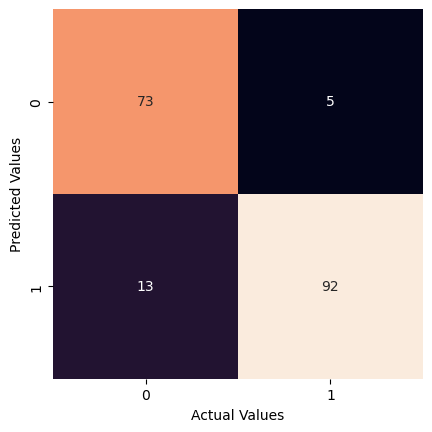

In [112]:
mat_imp = confusion_matrix(y_test['cancer_type'],y_pred)
sn.heatmap(mat_imp,square=True, annot=True, fmt='d', cbar=False)
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")

In [113]:
from sklearn.metrics import roc_curve, auc
y_scores = grid_search.predict_proba(X_test)
fpr, tpr, thresholds = roc_curve(y_test['cancer_type'], y_scores[:, 1])
roc_auc = auc(fpr, tpr)
roc_auc

0.9560439560439561

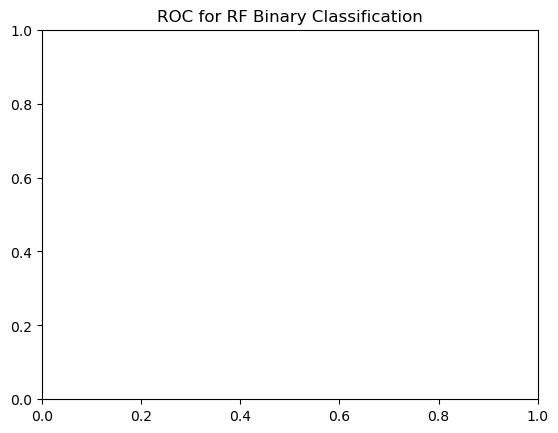

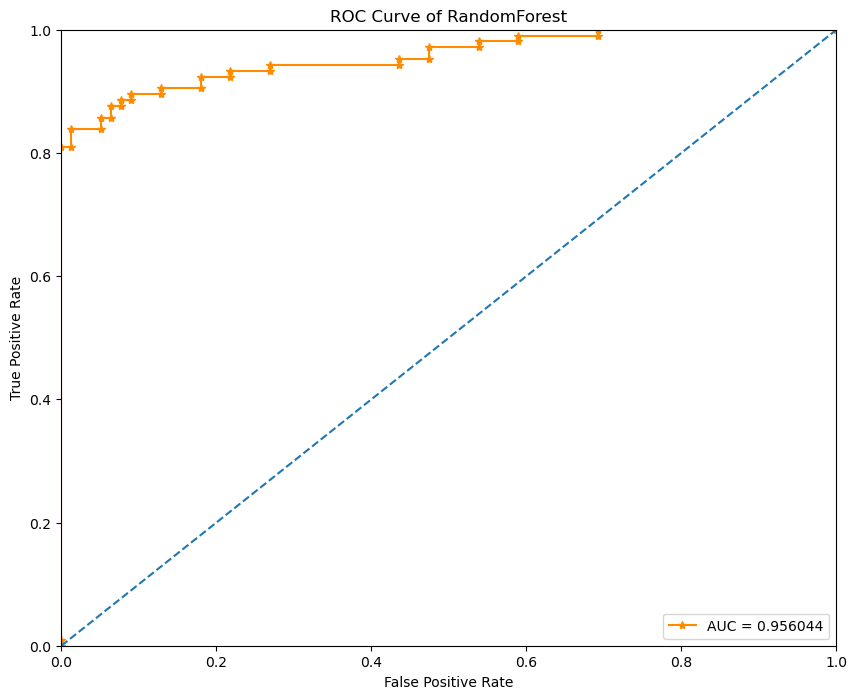

In [114]:
plt.title('ROC for RF Binary Classification')
plt.figure(figsize=(10,8))
plt.plot(fpr,tpr, marker = '*',color='darkorange',label = 'AUC = %0.6f' % roc_auc)
plt.legend(loc = 'lower right')
plt.plot([0, 1], [0, 1],'--')
plt.xlim([0, 1])
plt.ylim([0, 1])
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate')
plt.title('ROC Curve of RandomForest')
plt.show()

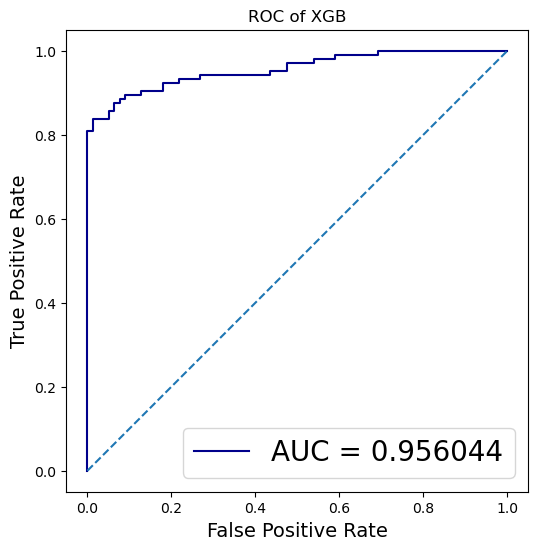

In [115]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))
plt.title('ROC of XGB')
plt.plot(fpr, tpr, color='darkblue', label='AUC = %0.6f' % roc_auc)
plt.legend(loc='lower right', fontsize=20)
plt.plot([0, 1], [0, 1], linestyle='--')
plt.axis('scaled')
plt.ylabel('True Positive Rate', fontsize=14)
plt.xlabel('False Positive Rate', fontsize=14)
plt.show()


# Shap

In [116]:
# SHAP prerequisites check
if 'grid_search' not in locals():
    raise RuntimeError('grid_search is not defined. Run the model training cells before SHAP.')

In [117]:
import shap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [118]:
# --- 1) Prepare model and SHAP-ready data ---
best_estimator = grid_search.best_estimator_
print(f"Best estimator type: {type(best_estimator).__name__}")

# Recover feature names with priority:
# 1) Saved names before scaling, 2) DataFrame columns, 3) best_genes, 4) fallback labels
if 'gene_names_selected' in locals() and len(gene_names_selected) == np.asarray(X_train).shape[1]:
    feature_names = list(gene_names_selected)
elif isinstance(X_train, pd.DataFrame):
    feature_names = X_train.columns.tolist()
elif 'best_genes' in locals() and len(best_genes) >= np.asarray(X_train).shape[1]:
    feature_names = list(best_genes[:np.asarray(X_train).shape[1]])
else:
    feature_names = [f"Gene_{i}" for i in range(np.asarray(X_train).shape[1])]

X_train_shap = pd.DataFrame(np.asarray(X_train), columns=feature_names)
X_test_shap = pd.DataFrame(np.asarray(X_test), columns=feature_names)

# Use a subset for speed/stability with KernelExplainer
n_background = min(100, len(X_train_shap))
n_explain = min(80, len(X_test_shap))
background = shap.sample(X_train_shap, n_background, random_state=42)
X_explain = shap.sample(X_test_shap, n_explain, random_state=42)

# --- 2) Build SHAP explainer ---
# For SVC with non-linear kernels, KernelExplainer is the most robust choice.
def predict_pos_class(data):
    return best_estimator.predict_proba(data)[:, 1]

explainer = shap.KernelExplainer(predict_pos_class, background)
print("Calculating SHAP values... (this can take a while)")
shap_values = explainer.shap_values(X_explain, nsamples=200)

# Handle SHAP output shape across versions
if isinstance(shap_values, list):
    # Older SHAP can return [class0, class1]
    shap_matrix = np.asarray(shap_values[1])
else:
    shap_matrix = np.asarray(shap_values)
    if shap_matrix.ndim == 3:
        # (samples, features, classes) -> positive class
        shap_matrix = shap_matrix[:, :, 1]

print("SHAP matrix shape:", shap_matrix.shape)

Best estimator type: XGBClassifier
Calculating SHAP values... (this can take a while)


  0%|          | 0/80 [00:00<?, ?it/s]

SHAP matrix shape: (80, 76)


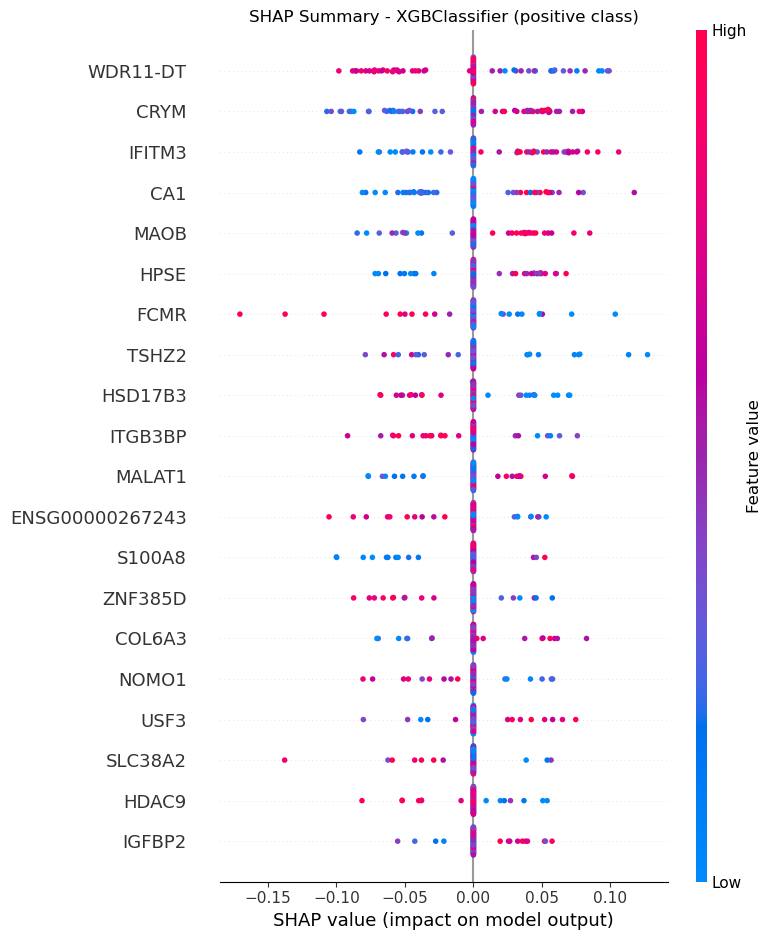

Top 10 Gene Biomarkers:
        Gene  SHAP_Abs_Mean
0   WDR11-DT       0.035720
14      CRYM       0.035153
3     IFITM3       0.028484
29       CA1       0.023033
25      MAOB       0.017122
12      HPSE       0.015454
39      FCMR       0.014585
67     TSHZ2       0.013569
4    HSD17B3       0.013518
6    ITGB3BP       0.011844


In [119]:
# --- 3) Plot SHAP summary ---
plt.figure(figsize=(12, 8))
shap.summary_plot(
    shap_matrix,
    features=X_explain,
    feature_names=feature_names,
    show=False
)
plt.title(f"SHAP Summary - {type(best_estimator).__name__} (positive class)")
plt.tight_layout()
plot_name = f"shap_summary_{type(best_estimator).__name__}.png"
# plt.savefig(plot_name, bbox_inches='tight', dpi=300)
plt.show()

# --- 4) Export ranked biomarkers ---
mean_abs_shap = np.abs(shap_matrix).mean(axis=0)
importance_df = pd.DataFrame({
    'Gene': feature_names,
    'SHAP_Abs_Mean': mean_abs_shap
}).sort_values(by='SHAP_Abs_Mean', ascending=False)

print("Top 10 Gene Biomarkers:")
print(importance_df.head(10))


In [120]:

importance_df.to_csv(r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2\Binary\SHAP\SHAP_xgb.csv", index=False)
print(f"Saved SHAP plot to: {plot_name}")

Saved SHAP plot to: shap_summary_XGBClassifier.png
